In [ ]:

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec
from gensim.models.phrases import Phrases, Phraser
from gensim import corpora
from gensim.models import LdaModel
from pprint import pprint
import random
import numpy as np
from nltk.sentiment import SentimentIntensityAnalyzer
from collections import Counter


from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/abcnews-date-text.csv")

In [ ]:
df.head()

,publish_date,headline_text
0,20030219,aba decides against community broadcasting lic...
1,20030219,act fire witnesses must be aware of defamation
2,20030219,a g calls for infrastructure protection summit
3,20030219,air nz staff in aust strike for pay rise
4,20030219,air nz strike to affect australian travellers


In [ ]:
df.shape

(1244184, 2)

In [ ]:
df.isnull()

,publish_date,headline_text
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
1244179,False,False
1244180,False,False
1244181,False,False
1244182,False,False


In [ ]:
df.describe()

,publish_date
count,1.244184e+06
mean,2.011021e+07
std,4.841151e+04
min,2.003022e+07
25%,2.007062e+07
50%,2.011062e+07
75%,2.015022e+07
max,2.021123e+07


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1244184 entries, 0 to 1244183
Data columns (total 2 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   publish_date   1244184 non-null  int64 
 1   headline_text  1244184 non-null  object
dtypes: int64(1), object(1)
memory usage: 19.0+ MB


In [ ]:
print("Unique headline_text: {}".format(len(df['headline_text'].unique())))
print("All headline_text: {}".format(len(df['headline_text'])))

Unique headline_text: 1213004
All headline_text: 1244184


In [ ]:



# Define a function to perform text cleaning
def clean_text(text):
    # Remove special characters, punctuation marks, and numeric digits
    cleaned_text = re.sub(r'[^a-zA-Z\s]', '', text)
    cleaned_text = re.sub(r'\s+', ' ', cleaned_text)  # Remove extra whitespaces
    return cleaned_text.strip()

# Apply text cleaning to the 'headline_text' column and create a new column 'cleaned_text'
df['cleaned_text'] = df['headline_text'].apply(clean_text)

# Display the updated DataFrame
print(df.head())


   publish_date                                      headline_text  \
0      20030219  aba decides against community broadcasting lic...   
1      20030219     act fire witnesses must be aware of defamation   
2      20030219     a g calls for infrastructure protection summit   
3      20030219           air nz staff in aust strike for pay rise   
4      20030219      air nz strike to affect australian travellers   

                                        cleaned_text  
0  aba decides against community broadcasting lic...  
1     act fire witnesses must be aware of defamation  
2     a g calls for infrastructure protection summit  
3           air nz staff in aust strike for pay rise  
4      air nz strike to affect australian travellers  


In [ ]:
df.head()

,publish_date,headline_text,cleaned_text
0,20030219,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...
1,20030219,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation
2,20030219,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit
3,20030219,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise
4,20030219,air nz strike to affect australian travellers,air nz strike to affect australian travellers


In [ ]:




# Define a function to perform text cleaning and lowercasing
def clean_text(text):
    # Remove special characters, punctuation marks, and numeric digits
    cleaned_text = re.sub(r'[^a-zA-Z\s]', '', text)
    cleaned_text = re.sub(r'\s+', ' ', cleaned_text)  # Remove extra whitespaces
    cleaned_text = cleaned_text.lower()  # Convert to lowercase
    return cleaned_text.strip()

# Apply text cleaning and lowercasing to the 'headline_text' column and create a new column 'cleaned_text'
df['cleaned_lowercased_text'] = df['headline_text'].apply(clean_text)

# Display the updated DataFrame
print(df.head())


   publish_date                                      headline_text  \
0      20030219  aba decides against community broadcasting lic...   
1      20030219     act fire witnesses must be aware of defamation   
2      20030219     a g calls for infrastructure protection summit   
3      20030219           air nz staff in aust strike for pay rise   
4      20030219      air nz strike to affect australian travellers   

                                        cleaned_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz staff in aust strike for pay rise   
4      air nz strike to affect australian travellers   

                             cleaned_lowercased_text  
0  aba decides against community broadcasting lic...  
1     act fire witnesses must be aware of defamation  
2     a g calls for infrastructure protection summit  
3           air nz sta

In [ ]:
df.head()

,publish_date,headline_text,cleaned_text,cleaned_lowercased_text
0,20030219,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...
1,20030219,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation
2,20030219,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit
3,20030219,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise
4,20030219,air nz strike to affect australian travellers,air nz strike to affect australian travellers,air nz strike to affect australian travellers


In [ ]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:




# Define a function to perform text cleaning, lowercasing, and tokenization
def tokenize_text(text):
    # Remove special characters, punctuation marks, and numeric digits
    cleaned_text = re.sub(r'[^a-zA-Z\s]', '', text)
    cleaned_text = re.sub(r'\s+', ' ', cleaned_text)  # Remove extra whitespaces
    cleaned_text = cleaned_text.lower()  # Convert to lowercase
    
    # Tokenize the text into individual words
    tokens = word_tokenize(cleaned_text)
    
    return tokens

# Apply text cleaning, lowercasing, and tokenization to the 'headline_text' column and create a new column 'tokens'
df['tokens'] = df['headline_text'].apply(tokenize_text)

# Display the updated DataFrame
print(df.head())

   publish_date                                      headline_text  \
0      20030219  aba decides against community broadcasting lic...   
1      20030219     act fire witnesses must be aware of defamation   
2      20030219     a g calls for infrastructure protection summit   
3      20030219           air nz staff in aust strike for pay rise   
4      20030219      air nz strike to affect australian travellers   

                                        cleaned_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz staff in aust strike for pay rise   
4      air nz strike to affect australian travellers   

                             cleaned_lowercased_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz

In [ ]:
df.head()

,publish_date,headline_text,cleaned_text,cleaned_lowercased_text,tokens
0,20030219,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,"[aba, decides, against, community, broadcastin..."
1,20030219,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,"[act, fire, witnesses, must, be, aware, of, de..."
2,20030219,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,"[a, g, calls, for, infrastructure, protection,..."
3,20030219,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,"[air, nz, staff, in, aust, strike, for, pay, r..."
4,20030219,air nz strike to affect australian travellers,air nz strike to affect australian travellers,air nz strike to affect australian travellers,"[air, nz, strike, to, affect, australian, trav..."


In [ ]:




# Load the dataset
data = pd.read_csv('your_dataset.csv')

# Define a function to perform text cleaning, lowercasing, tokenization, and stopword removal
def tokenize_text(text):
    # Remove special characters, punctuation marks, and numeric digits
    cleaned_text = re.sub(r'[^a-zA-Z\s]', '', text)
    cleaned_text = re.sub(r'\s+', ' ', cleaned_text)  # Remove extra whitespaces
    cleaned_text = cleaned_text.lower()  # Convert to lowercase
    
    # Tokenize the text into individual words
    tokens = word_tokenize(cleaned_text)
    
    # Remove stopwords
    stop_words = set(stopwords.words('english'))
    tokens = [token for token in tokens if token not in stop_words]
    
    return tokens

# Apply text cleaning, lowercasing, tokenization, and stopword removal to the 'headline_text' column and create a new column 'tokens'
data['tokens'] = data['headline_text'].apply(tokenize_text)

# Display the updated DataFrame
print(data.head())


In [ ]:
import nltk
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:




# Define a function to remove stopwords
def remove_stopwords(text):
    # Define the list of stopwords
    stopwords_list = set(stopwords.words('english'))
    
    # Tokenize the text
    tokens = word_tokenize(text)
    
    # Remove stopwords
    tokens = [token for token in tokens if token.lower() not in stopwords_list]
    
    # Join the tokens back into a single string
    processed_text = ' '.join(tokens)
    
    return processed_text

# Apply stopword removal to the 'headline_text' column and create a new column 'cleaned_text'
df['stopwords_removed'] = df['headline_text'].apply(remove_stopwords)

# Display the updated DataFrame
print(df.head())


   publish_date                                      headline_text  \
0      20030219  aba decides against community broadcasting lic...   
1      20030219     act fire witnesses must be aware of defamation   
2      20030219     a g calls for infrastructure protection summit   
3      20030219           air nz staff in aust strike for pay rise   
4      20030219      air nz strike to affect australian travellers   

                                        cleaned_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz staff in aust strike for pay rise   
4      air nz strike to affect australian travellers   

                             cleaned_lowercased_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz

In [ ]:
df.head()

,publish_date,headline_text,cleaned_text,cleaned_lowercased_text,tokens,stopwords_removed
0,20030219,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,"[aba, decides, against, community, broadcastin...",aba decides community broadcasting licence
1,20030219,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,"[act, fire, witnesses, must, be, aware, of, de...",act fire witnesses must aware defamation
2,20030219,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,"[a, g, calls, for, infrastructure, protection,...",g calls infrastructure protection summit
3,20030219,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,"[air, nz, staff, in, aust, strike, for, pay, r...",air nz staff aust strike pay rise
4,20030219,air nz strike to affect australian travellers,air nz strike to affect australian travellers,air nz strike to affect australian travellers,"[air, nz, strike, to, affect, australian, trav...",air nz strike affect australian travellers


In [ ]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [ ]:


# Define a function for lemmatization
def lemmatize_text(text):
    lemmatizer = WordNetLemmatizer()
    
    # Tokenize the text
    tokens = word_tokenize(text)
    
    # Lemmatize each token
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in tokens]
    
    # Join the lemmatized tokens back into a single string
    processed_text = ' '.join(lemmatized_tokens)
    
    return processed_text

# Apply lemmatization to the 'headline_text' column and create a new column 'cleaned_text'
df['lemmatized_text'] = df['headline_text'].apply(lemmatize_text)

# Display the updated DataFrame
print(df.head())


   publish_date                                      headline_text  \
0      20030219  aba decides against community broadcasting lic...   
1      20030219     act fire witnesses must be aware of defamation   
2      20030219     a g calls for infrastructure protection summit   
3      20030219           air nz staff in aust strike for pay rise   
4      20030219      air nz strike to affect australian travellers   

                                        cleaned_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz staff in aust strike for pay rise   
4      air nz strike to affect australian travellers   

                             cleaned_lowercased_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz

In [ ]:
df.head()

,publish_date,headline_text,cleaned_text,cleaned_lowercased_text,tokens,stopwords_removed,lemmatized_text
0,20030219,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,"[aba, decides, against, community, broadcastin...",aba decides community broadcasting licence,aba decides against community broadcasting lic...
1,20030219,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,"[act, fire, witnesses, must, be, aware, of, de...",act fire witnesses must aware defamation,act fire witness must be aware of defamation
2,20030219,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,"[a, g, calls, for, infrastructure, protection,...",g calls infrastructure protection summit,a g call for infrastructure protection summit
3,20030219,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,"[air, nz, staff, in, aust, strike, for, pay, r...",air nz staff aust strike pay rise,air nz staff in aust strike for pay rise
4,20030219,air nz strike to affect australian travellers,air nz strike to affect australian travellers,air nz strike to affect australian travellers,"[air, nz, strike, to, affect, australian, trav...",air nz strike affect australian travellers,air nz strike to affect australian traveller


In [ ]:

# Define the minimum length for a word/token
min_word_length = 3

# Remove short words/tokens
df['short_sentence'] = df['headline_text'].apply(lambda x: ' '.join([word for word in x.split() if len(word) >= min_word_length]))

# Display the updated DataFrame
print(df.head())

   publish_date                                      headline_text  \
0      20030219  aba decides against community broadcasting lic...   
1      20030219     act fire witnesses must be aware of defamation   
2      20030219     a g calls for infrastructure protection summit   
3      20030219           air nz staff in aust strike for pay rise   
4      20030219      air nz strike to affect australian travellers   

                                        cleaned_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz staff in aust strike for pay rise   
4      air nz strike to affect australian travellers   

                             cleaned_lowercased_text  \
0  aba decides against community broadcasting lic...   
1     act fire witnesses must be aware of defamation   
2     a g calls for infrastructure protection summit   
3           air nz

In [ ]:
df.head()

,publish_date,headline_text,cleaned_text,cleaned_lowercased_text,tokens,stopwords_removed,lemmatized_text,short_sentence
0,20030219,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...,"[aba, decides, against, community, broadcastin...",aba decides community broadcasting licence,aba decides against community broadcasting lic...,aba decides against community broadcasting lic...
1,20030219,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,act fire witnesses must be aware of defamation,"[act, fire, witnesses, must, be, aware, of, de...",act fire witnesses must aware defamation,act fire witness must be aware of defamation,act fire witnesses must aware defamation
2,20030219,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,a g calls for infrastructure protection summit,"[a, g, calls, for, infrastructure, protection,...",g calls infrastructure protection summit,a g call for infrastructure protection summit,calls for infrastructure protection summit
3,20030219,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,air nz staff in aust strike for pay rise,"[air, nz, staff, in, aust, strike, for, pay, r...",air nz staff aust strike pay rise,air nz staff in aust strike for pay rise,air staff aust strike for pay rise
4,20030219,air nz strike to affect australian travellers,air nz strike to affect australian travellers,air nz strike to affect australian travellers,"[air, nz, strike, to, affect, australian, trav...",air nz strike affect australian travellers,air nz strike to affect australian traveller,air strike affect australian travellers


In [ ]:
headline=df['headline_text']

In [ ]:
!pip install langid

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 21.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langid: filename=langid-1.1.6-py3-none-any.whl size=1941171 sha256=0e1d9da913818dd08badf59d4ecc03d2f14570156fcbc956f338af619d07c5f6
  Stored in directory: /root/.cache/pip/wheels/23/c8/c6/eed80894918490a175677414d40bd7c851413bbe03d4856c3c
Successfully built langid


In [ ]:
import langid

In [ ]:
df=df[:1000]

en    846
es     24
fr     21
da     20
de     16
Name: language, dtype: int64


<Axes: title={'center': 'Top 5 most common languages'}, ylabel='language'>

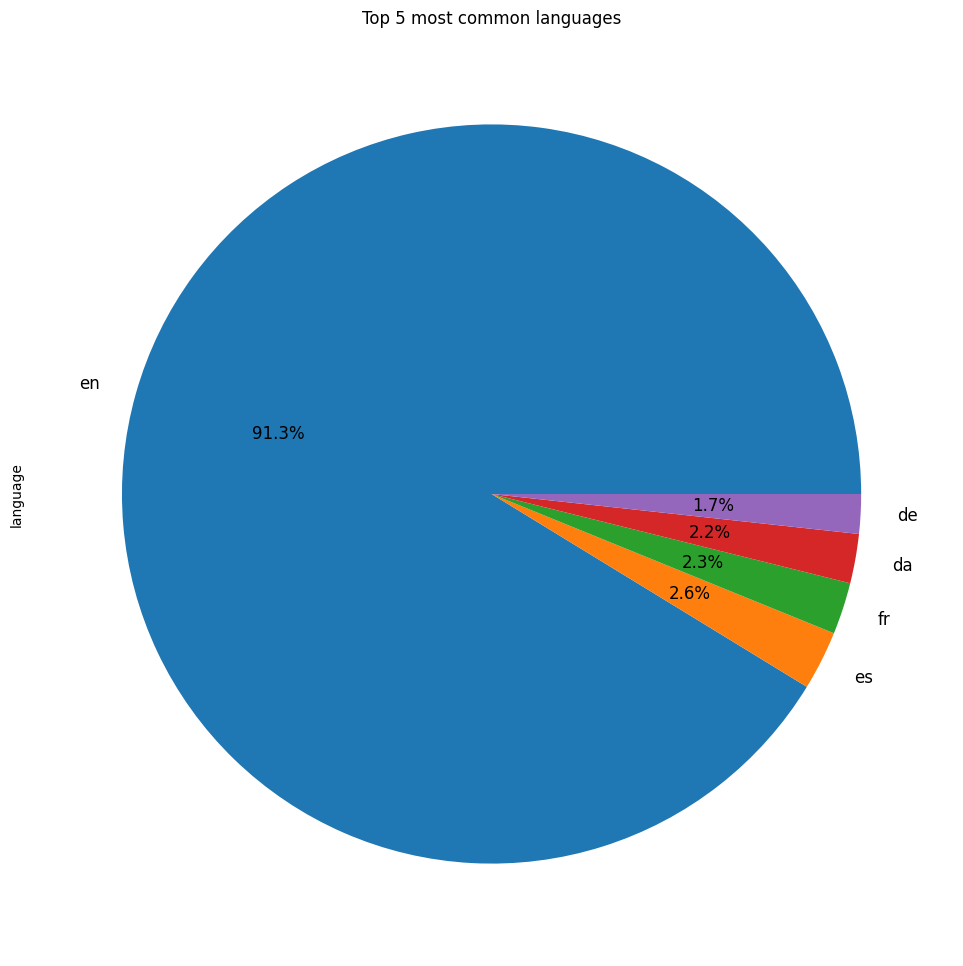

In [ ]:
predicted_languages = [langid.classify(headline) for headline in df['headline_text']]

lang_df = pd.DataFrame(predicted_languages, columns=['language','value'])

# show the top ten languages & their counts
print(lang_df['language'].value_counts().head(5))

# plot the counts for the top ten most commonly used languages
colors=sns.color_palette('hls', 20) 
pd.Series(lang_df['language']).value_counts().head(5).plot(kind = "pie",
                                                        figsize=(12,12),
                                                        fontsize=12,autopct='%1.1f%%',
                                                        title = "Top 5 most common languages")

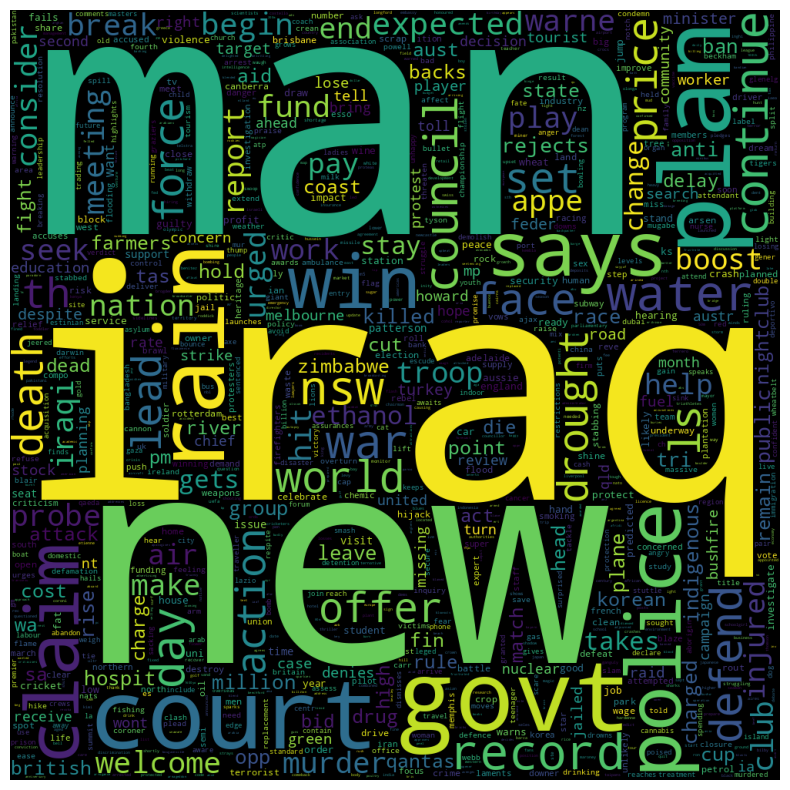

In [ ]:
junk = re.compile("al|RT|\n|&.*?;|http[s](?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+)*")
headline_text = [junk.sub(" ", t) for t in df.headline_text]

vec = TfidfVectorizer(stop_words='english', ngram_range=(1,2), max_df=.5)
tfv = vec.fit_transform(headline_text)

terms = vec.get_feature_names_out()
wc = WordCloud(height=1000, width=1000, max_words=1000).generate(" ".join(terms))

plt.figure(figsize=(10, 10))
plt.imshow(wc)
plt.axis("off")
plt.show()

In [ ]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize


# For word lemmitization
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:


# Preprocessing
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove numbers and punctuation
    text = re.sub(r'\d+|\W+', ' ', text)
    
    # Tokenization
    tokens = text.split()
    
    # Remove stopwords
    tokens = [token for token in tokens if token not in stop_words]
    
    return tokens

# Apply preprocessing to headlines
df['preprocessed_text'] = df['headline_text'].apply(preprocess_text)

# Train word2vec model
sentences = df['preprocessed_text'].tolist()
model = Word2Vec(sentences, window=5, min_count=5, workers=4)

# Example: Retrieve word embeddings for a specific word
word = 'man'
if word in model.wv:
    embedding = model.wv[word]
    print(f"Word Embedding for '{word}': {embedding}")
else:
    print(f"No word embedding found for '{word}'")

# Example: Find similar words to a given word
similar_words = model.wv.most_similar('man', topn=5)
print(f"Similar words to 'iraq': {similar_words}")


Word Embedding for 'man': [-0.00859172  0.00390658  0.005103    0.00580257  0.00737185 -0.0065041
  0.00119399  0.0064705  -0.00309736 -0.00629565 -0.00032029 -0.00858825
 -0.00565469  0.00721063  0.00322972  0.00725746  0.00691984  0.00718709
 -0.0038598  -0.0009612   0.00229865 -0.00450911  0.00850602 -0.01004121
  0.00664261  0.00306398 -0.00496418  0.00425599 -0.00186088  0.00674978
  0.01004599 -0.00431184 -0.00044548 -0.0058401   0.00365858  0.00312501
  0.00694237  0.00593854  0.00956806  0.00891352  0.00796716 -0.0073384
 -0.00928971 -0.00044083 -0.00290826  0.00788727  0.00580091 -0.00164869
  0.00155629  0.00183893  0.00786075 -0.00963023 -0.0001966   0.00352094
 -0.00083268  0.00857816  0.00908007  0.00651682 -0.00088609  0.00791374
 -0.00853125  0.00327344 -0.00443964 -0.0052288   0.00334707  0.00558272
  0.00786382 -0.00555817  0.00728744  0.00683041 -0.00391416 -0.00861212
  0.00546855  0.00650134 -0.00047059 -0.00656338 -0.00713565 -0.00253983
  0.00489352 -0.00350807 -0

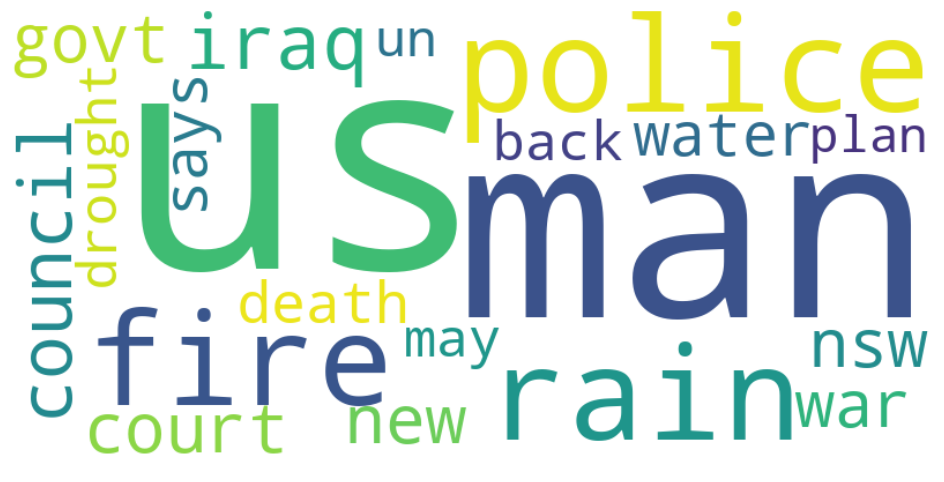

In [ ]:



# Preprocessing
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove numbers and punctuation
    text = re.sub(r'\d+|\W+', ' ', text)
    
    # Tokenization
    tokens = text.split()
    
    # Remove stopwords
    tokens = [token for token in tokens if token not in stop_words]
    
    return tokens

# Apply preprocessing to headlines
df['preprocessed_text'] = df['headline_text'].apply(preprocess_text)

# Calculate word frequencies
word_counts = Counter([word for headline in df['preprocessed_text'] for word in headline])

# Sort words by frequency
top_words = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)

# Extract the top 20 words
top_words = top_words[:20]

# Create a word cloud visualization
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(dict(top_words))

# Plot the word cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()


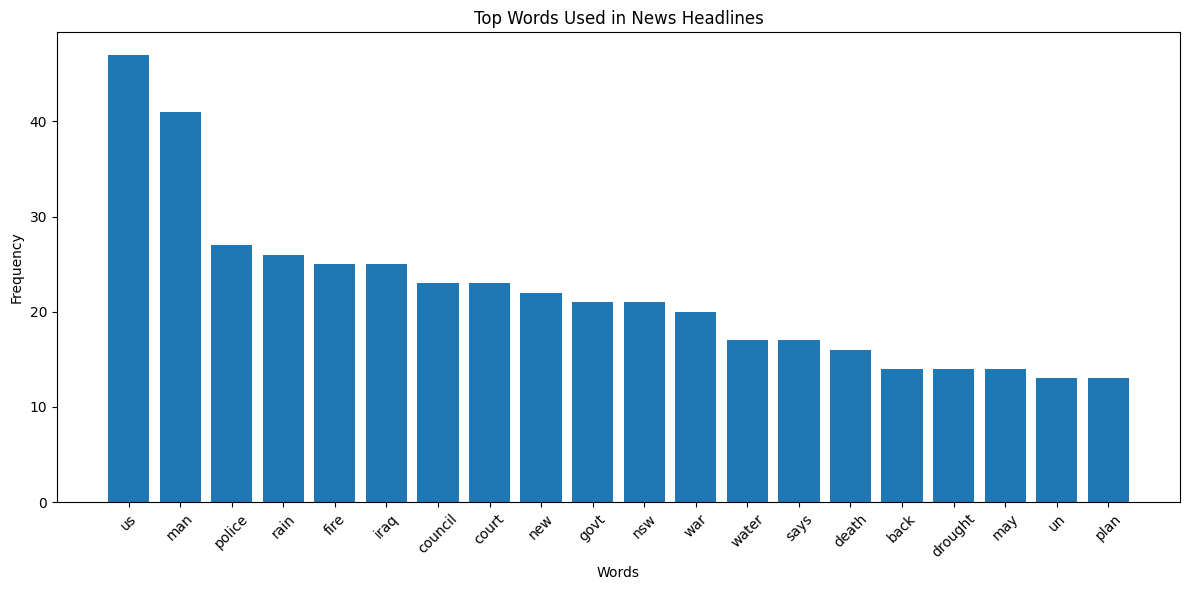

In [ ]:




# Preprocessing
stop_words = set(stopwords.words('english'))



# Calculate word frequencies
word_counts = Counter([word for headline in df['preprocessed_text'] for word in headline])

# Sort words by frequency
top_words = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)

# Extract the top 20 words
top_words = top_words[:20]

# Create bar chart
words = [word[0] for word in top_words]
frequencies = [word[1] for word in top_words]

plt.figure(figsize=(12, 6))
plt.bar(words, frequencies)
plt.xticks(rotation=45)
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.title('Top Words Used in News Headlines')
plt.tight_layout()
plt.show()


In [ ]:
import nltk
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

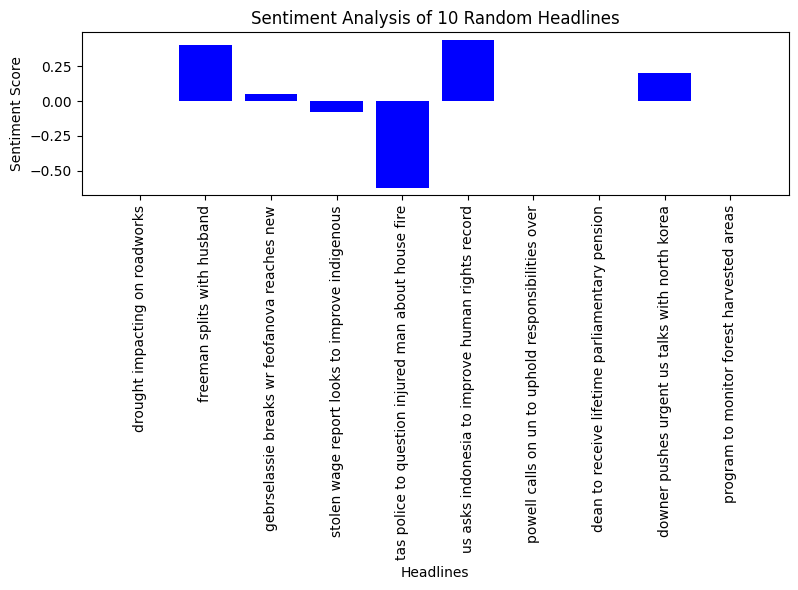

In [ ]:




# Select a random sample of 10 headlines
sample = df.sample(n=10, random_state=42)

# Perform sentiment analysis on the headlines
sia = SentimentIntensityAnalyzer()
sample['sentiment_score'] = sample['headline_text'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Plot the sentiment analysis results
plt.figure(figsize=(8, 6))
plt.bar(range(len(sample)), sample['sentiment_score'], color='blue')
plt.xticks(range(len(sample)), sample['headline_text'], rotation=90)
plt.xlabel('Headlines')
plt.ylabel('Sentiment Score')
plt.title('Sentiment Analysis of 10 Random Headlines')
plt.tight_layout()
plt.show()


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/abcnews-date-text.csv", parse_dates=[0], infer_datetime_format=True)
reindexed_data = df['headline_text']
reindexed_data.index = df['publish_date']

df.head()

,publish_date,headline_text
0,2003-02-19,aba decides against community broadcasting lic...
1,2003-02-19,act fire witnesses must be aware of defamation
2,2003-02-19,a g calls for infrastructure protection summit
3,2003-02-19,air nz staff in aust strike for pay rise
4,2003-02-19,air nz strike to affect australian travellers


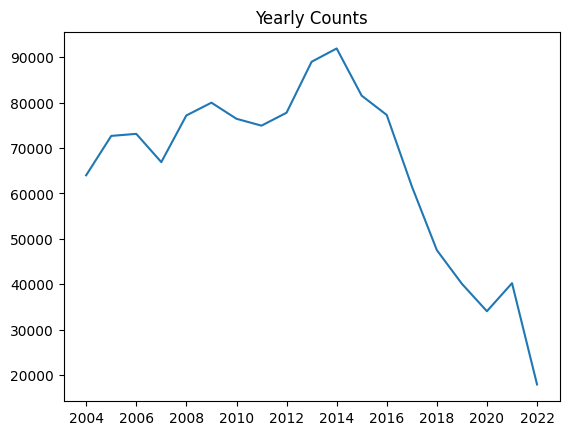

In [ ]:

yearly_counts = reindexed_data.resample('A').count()



plt.plot(yearly_counts);
plt.title('Yearly Counts');
plt.show()

In [ ]:
df=df[:10000]

In [ ]:
df.head()

,publish_date,headline_text
0,2003-02-19,aba decides against community broadcasting lic...
1,2003-02-19,act fire witnesses must be aware of defamation
2,2003-02-19,a g calls for infrastructure protection summit
3,2003-02-19,air nz staff in aust strike for pay rise
4,2003-02-19,air nz strike to affect australian travellers


In [ ]:



# Load the dataset

# Preprocessing
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove numbers and punctuation
    text = re.sub(r'\d+|\W+', ' ', text)
    
    # Tokenization
    tokens = text.split()
    
    # Remove stopwords
    tokens = [token for token in tokens if token not in stop_words]
    
    return tokens

# Apply preprocessing to headlines
df['preprocessed_text'] = df['headline_text'].apply(preprocess_text)

# Create bigrams/trigrams using Phrases
texts = df['preprocessed_text'].tolist()
bigram_phrases = Phrases(texts, min_count=5, threshold=100)
trigram_phrases = Phrases(bigram_phrases[texts], min_count=5, threshold=100)
bigram = Phraser(bigram_phrases)
trigram = Phraser(trigram_phrases)

# Apply bigram/trigram transformations to texts
texts = list(trigram[bigram[texts]])

# Create Word2Vec model
model = Word2Vec(sentences=texts, window=5, min_count=5, workers=4)

# Get word vectors
word_vectors = model.wv

# Perform topic modeling using LDA
dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]
lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=5, passes=10)

# Print topics and their top words
pprint(lda_model.print_topics(num_words=10))

# Example: Find similar words to a given word
similar_words = word_vectors.most_similar('war')
print('Similar words to "war":')
pprint(similar_words)


[(0,
  '0.015*"us" + 0.007*"war" + 0.007*"anti" + 0.006*"iraqi" + 0.005*"forces" + '
  '0.005*"fire" + 0.004*"call" + 0.004*"qld" + 0.004*"back" + 0.004*"govt"'),
 (1,
  '0.019*"man" + 0.017*"baghdad" + 0.014*"police" + 0.006*"charged" + '
  '0.005*"death" + 0.005*"woman" + 0.005*"probe" + 0.005*"car" + '
  '0.005*"missing" + 0.005*"crash"'),
 (2,
  '0.008*"win" + 0.006*"urged" + 0.005*"first" + 0.005*"south" + '
  '0.005*"world_cup" + 0.005*"lead" + 0.005*"title" + 0.004*"australian" + '
  '0.004*"open" + 0.004*"three"'),
 (3,
  '0.036*"iraq" + 0.027*"war" + 0.026*"us" + 0.011*"says" + 0.007*"iraqi" + '
  '0.006*"troops" + 0.006*"new" + 0.005*"may" + 0.005*"pm" + 0.005*"protest"'),
 (4,
  '0.012*"council" + 0.010*"govt" + 0.008*"two" + 0.007*"us" + 0.007*"nsw" + '
  '0.005*"drought" + 0.005*"may" + 0.004*"new" + 0.004*"killed" + '
  '0.004*"support"')]
Similar words to "war":
[('iraq', 0.9988723993301392),
 ('new', 0.9988473057746887),
 ('us', 0.9987667202949524),
 ('nsw', 0.998765587

In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:




# Preprocessing
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove numbers and punctuation
    text = re.sub(r'\d+|\W+', ' ', text)
    
    # Tokenization
    tokens = text.split()
    
    # Remove stopwords
    tokens = [token for token in tokens if token not in stop_words]
    
    return tokens

# Apply preprocessing to headlines
df['preprocessed_text'] = df['headline_text'].apply(preprocess_text)

# Create bigrams/trigrams using Phrases
texts = df['preprocessed_text'].tolist()
bigram_phrases = Phrases(texts, min_count=5, threshold=100)
trigram_phrases = Phrases(bigram_phrases[texts], min_count=5, threshold=100)
bigram = Phraser(bigram_phrases)
trigram = Phraser(trigram_phrases)

# Apply bigram/trigram transformations to texts
texts = list(trigram[bigram[texts]])

# Create Word2Vec model
model = Word2Vec(sentences=texts, window=5, min_count=5, workers=4)

# Get word vectors
word_vectors = model.wv

# Perform topic modeling using LDA
dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]
lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=5, passes=10)

# Print topics and their top words
pprint(lda_model.print_topics(num_words=10))

# Example: Find headlines containing a specific word
word_to_search = 'police'
similar_words = [word for word, similarity in word_vectors.most_similar(word_to_search)]
print('Similar words to "{}": {}'.format(word_to_search, similar_words))

# Find headlines containing similar words
matching_headlines = df[df['headline_text'].str.contains('|'.join(similar_words))]
print('Headlines containing similar words to "{}":'.format(word_to_search))
print(matching_headlines['headline_text'])


[(0,
  '0.019*"us" + 0.009*"iraq" + 0.008*"fire" + 0.008*"police" + 0.006*"un" + '
  '0.005*"back" + 0.004*"new" + 0.004*"turkey" + 0.004*"sa" + 0.004*"rain"'),
 (1,
  '0.007*"says" + 0.006*"win" + 0.004*"war" + 0.004*"injured" + 0.004*"coast" '
  '+ 0.004*"new" + 0.004*"man" + 0.003*"us" + 0.003*"set" + 0.003*"plan"'),
 (2,
  '0.011*"court" + 0.010*"man" + 0.007*"us" + 0.005*"war" + 0.005*"murder" + '
  '0.005*"nsw" + 0.005*"fire" + 0.005*"new" + 0.005*"charged" + 0.005*"face"'),
 (3,
  '0.009*"death" + 0.006*"man" + 0.006*"go" + 0.005*"council" + 0.005*"world" '
  '+ 0.004*"funds" + 0.004*"patterson" + 0.004*"show" + 0.004*"police" + '
  '0.004*"mp"'),
 (4,
  '0.007*"council" + 0.006*"rain" + 0.006*"day" + 0.006*"govt" + 0.005*"one" + '
  '0.005*"plan" + 0.004*"may" + 0.004*"man" + 0.004*"nsw" + 0.004*"appeal"')]
Similar words to "police": ['match', 'warne', 'petrol', 'korean', 'new', 'aid', 'seek', 'rejects', 'war', 'final']
Headlines containing similar words to "police":
1         

In [ ]:
# Calculate perplexity
perplexity = lda_model.log_perplexity(corpus)

print("Perplexity:", perplexity)

Perplexity: -8.439231894159859


In [ ]:
df.head()

,publish_date,headline_text,preprocessed_text
0,2003-02-19,aba decides against community broadcasting lic...,"[aba, decides, community, broadcasting, licence]"
1,2003-02-19,act fire witnesses must be aware of defamation,"[act, fire, witnesses, must, aware, defamation]"
2,2003-02-19,a g calls for infrastructure protection summit,"[g, calls, infrastructure, protection, summit]"
3,2003-02-19,air nz staff in aust strike for pay rise,"[air, nz, staff, aust, strike, pay, rise]"
4,2003-02-19,air nz strike to affect australian travellers,"[air, nz, strike, affect, australian, travellers]"


In [ ]:



# Preprocessing
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    
    # Remove numbers and punctuation
    text = re.sub(r'\d+|\W+', ' ', text)
    
    # Tokenization
    tokens = text.split()
    
    # Remove stopwords
    tokens = [token for token in tokens if token not in stop_words]
    
    return tokens

# Apply preprocessing to headlines
df['preprocessed_text'] = df['headline_text'].apply(preprocess_text)

# Create bigrams/trigrams using Phrases
texts = df['preprocessed_text'].tolist()
bigram_phrases = Phrases(texts, min_count=5, threshold=100)
trigram_phrases = Phrases(bigram_phrases[texts], min_count=5, threshold=100)
bigram = Phraser(bigram_phrases)
trigram = Phraser(trigram_phrases)

# Apply bigram/trigram transformations to texts
texts = list(trigram[bigram[texts]])

# Create Word2Vec model
model = Word2Vec(sentences=texts, window=5, min_count=5, workers=4)

# Function to find similar headlines
def find_similar_headlines(query_headline, top_n=5):
    preprocessed_query = preprocess_text(query_headline)
    
    # Filter words not present in the model's vocabulary
    preprocessed_query = [word for word in preprocessed_query if word in model.wv]
    
    if len(preprocessed_query) == 0:
        return []  # Return an empty list if no words are present in the model's vocabulary
    
    # Compute average vector of query headline
    query_vector = sum(model.wv[word] for word in preprocessed_query) / len(preprocessed_query)
    
    # Compute cosine similarity between query vector and headline vectors
    similarity_scores = cosine_similarity([query_vector], model.wv.vectors)[0]
    
    # Get indices of top-n most similar headlines
    top_indices = similarity_scores.argsort()[-top_n:][::-1]
    
    # Return the top-n similar headlines
    similar_headlines = [df.iloc[index]['headline_text'] for index in top_indices]
    return similar_headlines,similarity_scores

# Example usage: Find similar headlines to a given query headline
query = "aba decides against community broadcasting licence"
similar_headlines = find_similar_headlines(query, top_n=5)

print(f"Similar headlines to '{query}':")
for headline in similar_headlines:
    print(headline)


Similar headlines to 'aba decides against community broadcasting licence':
['low demand forces air service cuts', 'dying korean subway passengers phoned for help', 'big plan to boost paroo water supplies', 'uni to continue tree disease study', 'four injured in head on highway crash']
[-2.11983826e-02  4.96006571e-02 -6.46950230e-02 -2.77691707e-02
 -1.02055416e-01 -8.58901739e-02 -6.99707121e-02  2.99085025e-02
  5.49602062e-02 -6.32649064e-02 -1.08266436e-03  3.58969048e-02
  3.33182067e-02 -1.40799314e-01  1.92626536e-01 -6.94062859e-02
 -2.44966894e-02  1.56662852e-01  1.69594035e-01 -5.88227212e-02
 -1.22986354e-01 -1.31965607e-01 -1.37070671e-01 -8.12921822e-02
  1.25195116e-01  3.54166143e-02  1.81584060e-03  1.72922969e-01
  1.45207113e-03 -7.91405141e-02  1.06770739e-01  2.76806056e-02
  4.69415262e-02 -1.48360550e-01  4.02915254e-02  1.00734718e-01
 -9.71755907e-02 -1.81706250e-01 -1.31502733e-01 -1.02058277e-02
  6.50211871e-02  5.00699319e-03  1.75312996e-01  2.18928605e-01


In [ ]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [ ]:
df=df[:1000]

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


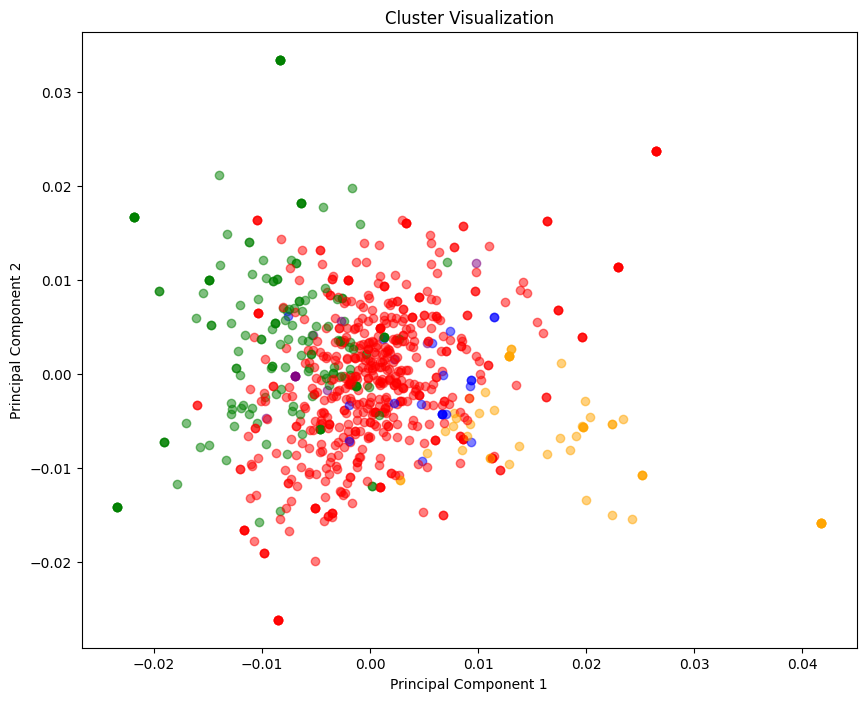

Cluster 1 Topics:
aba decides against community broadcasting licence
act fire witnesses must be aware of defamation
air nz staff in aust strike for pay rise
air nz strike to affect australian travellers
ambitious olsson wins triple jump
antic delighted with record breaking barca
aussie qualifier stosur wastes four memphis match
australia is locked into war timetable opp
australia to contribute 10 million in aid to iraq
barca take record as robson celebrates birthday in
big hopes for launceston cycling championship
big plan to boost paroo water supplies
brigadier dismisses reports troops harassed in
british combat troops arriving daily in kuwait
call for ethanol blend fuel to go ahead
carews freak goal leaves roma in ruins
council chief executive fails to secure position
councillor to contest wollongong as independent
council moves to protect tas heritage garden
council welcomes ambulance levy decision
crean tells alp leadership critics to shut up
death toll continues to climb in south 

In [ ]:



# Preprocess the df
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    tokens = word_tokenize(text.lower())  # Tokenize and convert to lowercase
    tokens = [token for token in tokens if token.isalpha()]  # Remove non-alphabetic tokens
    tokens = [token for token in tokens if token not in stop_words]  # Remove stopwords
    return tokens

df['preprocessed_text'] = df['headline_text'].apply(preprocess_text)

# Train Word2Vec model
sentences = df['preprocessed_text'].tolist()
model = Word2Vec(sentences=sentences, window=5, min_count=5, workers=4)

# Generate document embeddings
document_embeddings = []
for sentence in sentences:
    embeddings = [model.wv[word] for word in sentence if word in model.wv]
    if embeddings:
        avg_embedding = sum(embeddings) / len(embeddings)
        document_embeddings.append(avg_embedding)

# Apply K-means clustering
num_clusters = 5  # Adjust this value according to the optimal number of clusters
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
kmeans.fit(document_embeddings)
cluster_labels = kmeans.labels_

# Perform dimensionality reduction with PCA
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(document_embeddings)

# Visualize the clusters
plt.figure(figsize=(10, 8))
colors = ['red', 'blue', 'green', 'purple', 'orange']  # Customize the colors if needed

for i, embedding in enumerate(reduced_embeddings):
    plt.scatter(embedding[0], embedding[1], c=colors[cluster_labels[i]], alpha=0.5)

plt.title('Cluster Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

# Assign topics to clusters
cluster_topics = {}
for i in range(num_clusters):
    cluster_topics[i] = []

for i, label in enumerate(cluster_labels):
    cluster_topics[label].append(df.iloc[i]['headline_text'])

# Print topics in each cluster
for label, topics in cluster_topics.items():
    print(f"Cluster {label+1} Topics:")
    for topic in topics:
        print(topic)
    print()


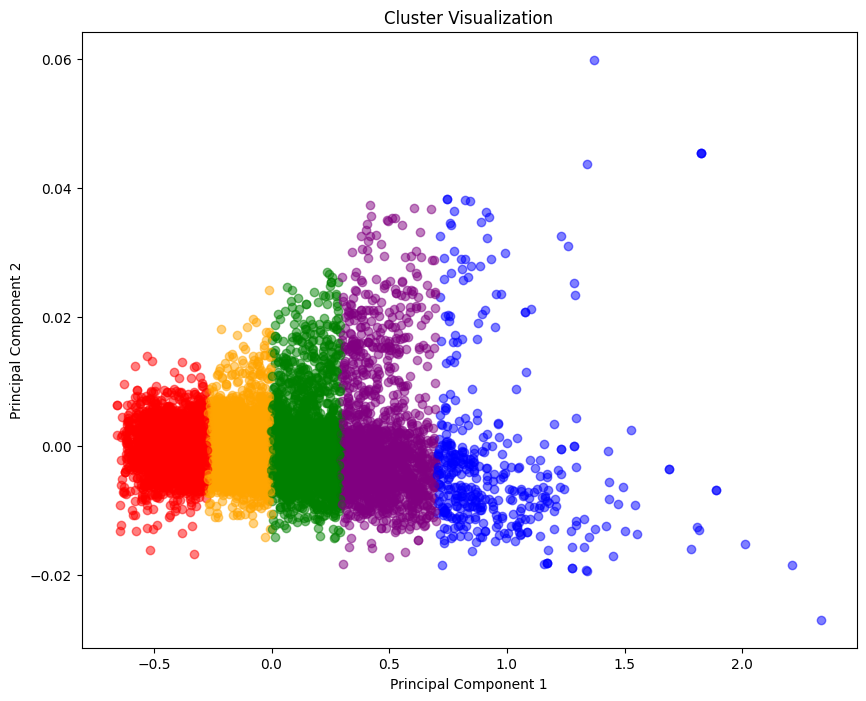

In [ ]:
# Visualize the clusters
plt.figure(figsize=(10, 8))
colors = ['red', 'blue', 'green', 'purple', 'orange']  # Customize the colors if needed

for i, embedding in enumerate(reduced_embeddings):
    plt.scatter(embedding[0], embedding[1], c=colors[cluster_labels[i]], alpha=0.5)

plt.title('Cluster Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()